# Waste Classification Using Convolutional Neural Network (CNN)

## Project Overview

This project focuses on developing a Convolutional Neural Network (CNN) model for automatic waste classification.

The model classifies waste images into two categories:

1. Organic Waste
2. Recyclable Waste

TensorFlow and Keras libraries are used to build, train, and evaluate the CNN model.

## Importing Required Libraries and Checking GPU Availability

TensorFlow is imported for building and training the CNN model.
GPU availability is checked to ensure faster model training.

In [1]:
import tensorflow as tf

print("TensorFlow Version:", tf.__version__)

print("GPU Available:", tf.config.list_physical_devices('GPU'))

TensorFlow Version: 2.20.0
GPU Available: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU'), PhysicalDevice(name='/physical_device:GPU:1', device_type='GPU')]


## Setting Up Waste Classification Dataset

The waste classification dataset is loaded from the Kaggle input directory. 
The dataset contains two categories of waste images: Organic Waste and Recyclable Waste. 
The directory structure is verified before performing data preprocessing and model training.

In [2]:
import os

dataset_path = "/kaggle/input/datasets/shaikhsameer372/waste-classification-dataset/Waste Classification Dataset/waste_dataset"

print(os.listdir(dataset_path))

['organic', 'waste_dataset_CNN.ipynb', 'waste_dataset_augmentation.ipynb', 'recyclable', 'waste_dataset_README.txt']


## Dataset Loading and Directory Setup

The waste classification dataset is loaded from the Kaggle input directory. 
The dataset contains two classes:

- Organic Waste
- Recyclable Waste

The directory structure is verified and the number of images in each class is counted before preprocessing and model training.

In [3]:
import os

dataset_path = "/kaggle/input/datasets/shaikhsameer372/waste-classification-dataset/Waste Classification Dataset/waste_dataset"

organic_path = os.path.join(dataset_path, "organic")
recyclable_path = os.path.join(dataset_path, "recyclable")

print("Organic folder:", organic_path)
print("Recyclable folder:", recyclable_path)

print("Organic images:", len(os.listdir(organic_path)))
print("Recyclable images:", len(os.listdir(recyclable_path)))

Organic folder: /kaggle/input/datasets/shaikhsameer372/waste-classification-dataset/Waste Classification Dataset/waste_dataset/organic
Recyclable folder: /kaggle/input/datasets/shaikhsameer372/waste-classification-dataset/Waste Classification Dataset/waste_dataset/recyclable
Organic images: 13880
Recyclable images: 10825


## Dataset Distribution Analysis

Before training the CNN model, the dataset distribution is analyzed to understand the number of images available in each class.

The dataset contains two waste categories:

1. Organic Waste
2. Recyclable Waste

This analysis helps evaluate the class balance and provides an overview of the dataset structure before model training.

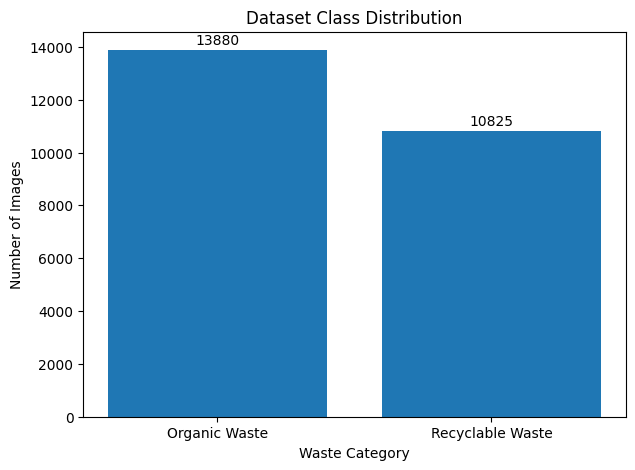

In [4]:
import matplotlib.pyplot as plt

classes = ['Organic Waste', 'Recyclable Waste']
counts = [len(os.listdir(organic_path)), len(os.listdir(recyclable_path))]

plt.figure(figsize=(7,5))

plt.bar(classes, counts)

plt.xlabel("Waste Category")
plt.ylabel("Number of Images")
plt.title("Dataset Class Distribution")

for i, count in enumerate(counts):
    plt.text(i, count + 200, str(count), ha='center')

plt.show()

## Sample Images from Dataset

To visually inspect the dataset quality, sample images from both waste categories are displayed.

The dataset contains two classes:

1. Organic Waste
2. Recyclable Waste

Displaying sample images helps verify the image quality, class labels, and proper organization of the dataset before CNN model training.

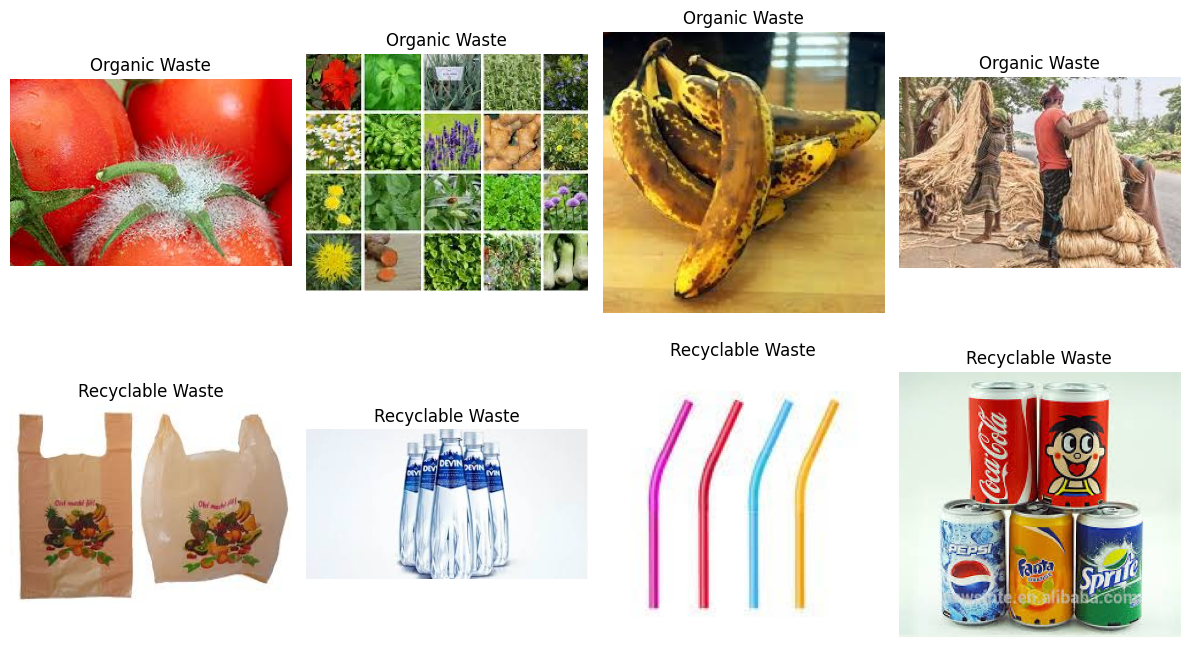

In [12]:
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
import random
import os


plt.figure(figsize=(12,7))


# Organic Waste Samples

organic_samples = random.sample(os.listdir(organic_path), 4)

for i, img_name in enumerate(organic_samples):
    
    img_path = os.path.join(organic_path, img_name)
    img = mpimg.imread(img_path)

    plt.subplot(2,4,i+1)
    plt.imshow(img)
    plt.title("Organic Waste")
    plt.axis("off")


# Recyclable Waste Samples

recyclable_samples = random.sample(os.listdir(recyclable_path), 4)

for i, img_name in enumerate(recyclable_samples):

    img_path = os.path.join(recyclable_path, img_name)
    img = mpimg.imread(img_path)

    plt.subplot(2,4,i+5)
    plt.imshow(img)
    plt.title("Recyclable Waste")
    plt.axis("off")


plt.tight_layout()
plt.show()

## Image Preprocessing and Data Augmentation

Before training the CNN model, image preprocessing and data augmentation techniques are applied to improve model performance and reduce overfitting.

The following preprocessing steps are performed:

1. Images are resized to a fixed dimension (128×128).
2. Pixel values are normalized using rescaling (1/255).
3. Data augmentation techniques such as rotation, zoom, and horizontal flipping are applied to improve model generalization.

The dataset is divided into training and validation sets for model evaluation.

In [13]:
from tensorflow.keras.preprocessing.image import ImageDataGenerator


IMG_SIZE = (128,128)
BATCH_SIZE = 64


train_datagen = ImageDataGenerator(
    rescale=1./255,
    rotation_range=20,
    zoom_range=0.2,
    horizontal_flip=True,
    validation_split=0.2
)


validation_datagen = ImageDataGenerator(
    rescale=1./255,
    validation_split=0.2
)


train_generator = train_datagen.flow_from_directory(
    dataset_path,
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode='binary',
    subset='training'
)


validation_generator = validation_datagen.flow_from_directory(
    dataset_path,
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode='binary',
    subset='validation',
    shuffle=False
)

Found 19764 images belonging to 2 classes.
Found 4941 images belonging to 2 classes.


## CNN Model Architecture

A basic Convolutional Neural Network (CNN) model is developed from scratch to classify waste images into two categories: Organic Waste and Recyclable Waste.

The CNN architecture consists of:

1. Convolutional layers for extracting important visual features from images.
2. MaxPooling layers for reducing spatial dimensions and computational complexity.
3. Global Average Pooling layer for converting feature maps into compact feature representations.
4. Dense layers for final classification.
5. Dropout layer to reduce overfitting and improve model generalization.

The final output layer uses sigmoid activation for binary classification.

In [15]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, Conv2D, MaxPooling2D, GlobalAveragePooling2D, Dense, Dropout


model = Sequential([

    Input(shape=(128,128,3)),

    Conv2D(32, (3,3), activation='relu'),
    MaxPooling2D(2,2),

    Conv2D(64, (3,3), activation='relu'),
    MaxPooling2D(2,2),

    Conv2D(128, (3,3), activation='relu'),
    MaxPooling2D(2,2),

    GlobalAveragePooling2D(),

    Dense(64, activation='relu'),
    Dropout(0.5),

    Dense(1, activation='sigmoid')
])


model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_3 (Conv2D)               │ (None, 126, 126, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 63, 63, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 61, 61, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 30, 30, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 28, 28, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_5 (MaxPooling2D)  │ (None, 14, 14, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_1      │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 101,569 (396.75 KB)

 Trainable params: 101,569 (396.75 KB)

 Non-trainable params: 0 (0.00 B)

## Model Compilation

Before starting the training process, the CNN model is compiled using a suitable optimizer, loss function, and evaluation metric.

Configuration:

- Optimizer: Adam optimizer is used for efficient gradient-based optimization.
- Loss Function: Binary Crossentropy is selected because the task is a binary classification problem.
- Evaluation Metric: Accuracy is used to measure classification performance.

The model summary displays the network architecture, output shapes, and trainable parameters.

In [17]:
model.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['accuracy']
)

model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_3 (Conv2D)               │ (None, 126, 126, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 63, 63, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 61, 61, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 30, 30, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 28, 28, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_5 (MaxPooling2D)  │ (None, 14, 14, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_1      │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 101,569 (396.75 KB)

 Trainable params: 101,569 (396.75 KB)

 Non-trainable params: 0 (0.00 B)

## Callback Configuration

Callbacks are used during CNN model training to improve performance.

- EarlyStopping stops training when validation loss does not improve.
- ModelCheckpoint saves the best model based on validation accuracy.

These callbacks help reduce overfitting and save the best performing model.

In [20]:
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint


early_stop = EarlyStopping(
    monitor='val_loss',
    patience=3,
    restore_best_weights=True
)


checkpoint = ModelCheckpoint(
    '/kaggle/working/best_waste_model.keras',
    monitor='val_accuracy',
    save_best_only=True,
    mode='max',
    verbose=1
)

## CNN Model Training

The CNN model is trained using the training dataset and evaluated using the validation dataset.

Training configuration:

- Epochs: 10
- Optimizer: Adam
- Early Stopping: Enabled to prevent overfitting
- Model Checkpoint: Enabled to save the best performing model

The model automatically saves the best performing model based on validation accuracy during training.

In [23]:
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint


early_stop = EarlyStopping(
    monitor='val_loss',
    patience=3,
    restore_best_weights=True
)


checkpoint = ModelCheckpoint(
    '/kaggle/working/best_waste_model.keras',
    monitor='val_accuracy',
    save_best_only=True,
    mode='max',
    verbose=1
)


history = model.fit(
    train_generator,
    validation_data=validation_generator,
    epochs=10,
    callbacks=[early_stop, checkpoint],
    verbose=1
)

Epoch 1/10
309/309 ━━━━━━━━━━━━━━━━━━━━ 0s 468ms/step - accuracy: 0.8085 - loss: 0.4501
Epoch 1: val_accuracy improved from None to 0.84639, saving model to /kaggle/working/best_waste_model.keras

Epoch 1: finished saving model to /kaggle/working/best_waste_model.keras
309/309 ━━━━━━━━━━━━━━━━━━━━ 176s 570ms/step - accuracy: 0.8100 - loss: 0.4436 - val_accuracy: 0.8464 - val_loss: 0.3632
Epoch 2/10
309/309 ━━━━━━━━━━━━━━━━━━━━ 0s 340ms/step - accuracy: 0.8247 - loss: 0.4117
Epoch 2: val_accuracy did not improve from 0.84639
309/309 ━━━━━━━━━━━━━━━━━━━━ 114s 369ms/step - accuracy: 0.8254 - loss: 0.4082 - val_accuracy: 0.8407 - val_loss: 0.3715
Epoch 3/10
309/309 ━━━━━━━━━━━━━━━━━━━━ 0s 326ms/step - accuracy: 0.8308 - loss: 0.3960
Epoch 3: val_accuracy improved from 0.84639 to 0.86986, saving model to /kaggle/working/best_waste_model.keras

Epoch 3: finished saving model to /kaggle/working/best_waste_model.keras
309/309 ━━━━━━━━━━━━━━━━━━━━ 110s 355ms/step - accuracy: 0.8379 - loss: 0.38

## Training Performance Visualization

The training performance of the CNN model is evaluated using accuracy and loss curves.

The accuracy curves represent the improvement of classification performance during training, while the loss curves show the reduction of prediction error over different epochs.

Both training and validation results are compared to analyze model learning behaviour and identify possible overfitting.

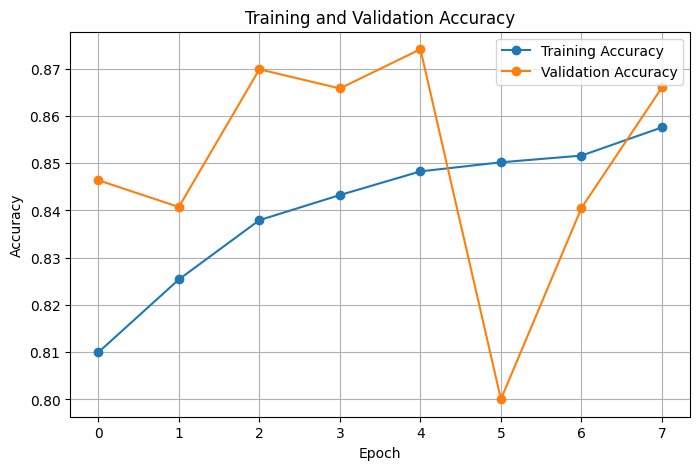

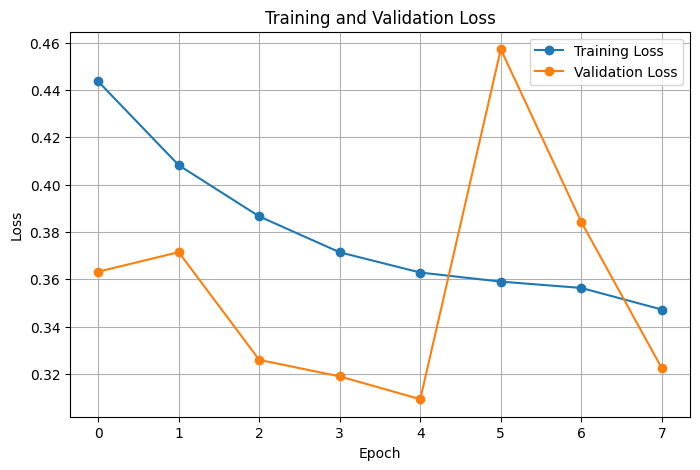

In [24]:
import matplotlib.pyplot as plt


# Accuracy Visualization

plt.figure(figsize=(8,5))

plt.plot(history.history['accuracy'], marker='o', label='Training Accuracy')
plt.plot(history.history['val_accuracy'], marker='o', label='Validation Accuracy')

plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.title('Training and Validation Accuracy')

plt.legend()
plt.grid(True)

plt.show()



# Loss Visualization

plt.figure(figsize=(8,5))

plt.plot(history.history['loss'], marker='o', label='Training Loss')
plt.plot(history.history['val_loss'], marker='o', label='Validation Loss')

plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.title('Training and Validation Loss')

plt.legend()
plt.grid(True)

plt.show()

## Training Performance Analysis

The accuracy graph shows that the CNN model gradually improves its classification ability as the number of epochs increases.

The validation accuracy follows a similar trend to the training accuracy, indicating that the model learns meaningful features from the dataset without significant overfitting.

The loss graph shows a continuous decrease in prediction error during training. The small difference between training loss and validation loss indicates good model generalization performance.

## Saving the Trained Model

The trained CNN model is saved in Keras format for future use.

The saved model can be loaded later to perform waste classification predictions without repeating the training process. This helps in reusing the trained model efficiently for future applications.

In [27]:
model.save("/kaggle/working/final_waste_model.keras")

## Model Evaluation

The trained CNN model is evaluated using the validation dataset to measure its performance on unseen waste images.

The evaluation process calculates validation loss and validation accuracy. These metrics help determine the prediction error and classification performance of the model.

In [28]:
loss, accuracy = model.evaluate(validation_generator)

print(f"Validation Loss: {loss:.4f}")
print(f"Validation Accuracy: {accuracy*100:.2f}%")

78/78 ━━━━━━━━━━━━━━━━━━━━ 8s 106ms/step - accuracy: 0.8741 - loss: 0.3094
Validation Loss: 0.3094
Validation Accuracy: 87.41%


The CNN model achieved a validation accuracy of 87.41%, demonstrating that the trained model can effectively classify different categories of waste images. The validation loss value also indicates that the model maintains good prediction performance on unseen data.

## Classification Report

A classification report is generated to evaluate the performance of the trained CNN model on different waste categories.

The report provides important evaluation metrics including:

• Precision: Measures how accurately the model predicts each waste category.
• Recall: Measures how effectively the model identifies actual samples of each category.
• F1-score: Represents the balance between precision and recall.
• Support: Shows the number of samples used for evaluation.

These metrics provide a detailed analysis of the CNN model's classification performance for Organic and Recyclable waste categories.

In [29]:
validation_generator.reset()

# Get true labels
y_true = validation_generator.classes

# Predict using trained model
y_pred = model.predict(validation_generator)

# Convert probability output into class labels
y_pred_classes = (y_pred > 0.5).astype(int).reshape(-1)

from sklearn.metrics import classification_report

report = classification_report(
    y_true,
    y_pred_classes,
    target_names=['Organic', 'Recyclable']
)

print(report)

78/78 ━━━━━━━━━━━━━━━━━━━━ 9s 106ms/step
              precision    recall  f1-score   support

     Organic       0.87      0.91      0.89      2776
  Recyclable       0.88      0.83      0.85      2165

    accuracy                           0.87      4941
   macro avg       0.87      0.87      0.87      4941
weighted avg       0.87      0.87      0.87      4941



## Loading the Best Saved Model

The best performing CNN model saved during training using ModelCheckpoint is loaded again for final evaluation and prediction.

Loading the saved model avoids retraining and allows the previously optimized model weights to be reused for waste classification tasks.

In [30]:
from tensorflow.keras.models import load_model

# Load the best saved model
best_model = load_model('/kaggle/working/best_waste_model.keras')

print("Best model loaded successfully.")

Best model loaded successfully.


## Confusion Matrix

A confusion matrix is generated to visualize the classification performance of the CNN model.

It shows the number of correct and incorrect predictions for each waste category and helps identify classification errors between Organic and Recyclable waste.

78/78 ━━━━━━━━━━━━━━━━━━━━ 9s 113ms/step


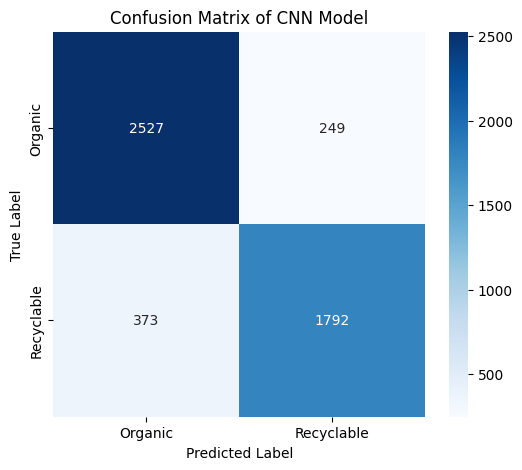

In [31]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

# Reset generator
validation_generator.reset()

# Get true labels
y_true = validation_generator.classes

# Predict using best model
y_pred = best_model.predict(validation_generator)

# Convert probabilities into class labels
y_pred_classes = (y_pred > 0.5).astype(int).reshape(-1)

# Generate confusion matrix
cm = confusion_matrix(y_true, y_pred_classes)

# Plot confusion matrix
plt.figure(figsize=(6,5))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['Organic','Recyclable'],
    yticklabels=['Organic','Recyclable']
)

plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.title('Confusion Matrix of CNN Model')

plt.show()

## Sample Waste Image Prediction

The trained CNN model is tested on sample waste images to verify its prediction capability.

The model predicts whether the given image belongs to the Organic or Recyclable waste category.

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 51ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 50ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 52ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 51ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 51ms/step


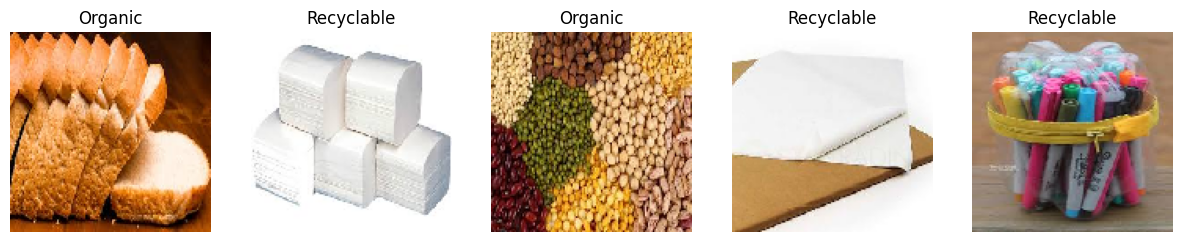

In [47]:
## Random Waste Image Prediction

import numpy as np
import matplotlib.pyplot as plt
import random

from tensorflow.keras.preprocessing import image


# Select 5 random images
sample_images = random.sample(validation_generator.filepaths, 5)


plt.figure(figsize=(15,10))


for i, sample_path in enumerate(sample_images):

    # Load image
    img = image.load_img(
        sample_path,
        target_size=(128,128)
    )

    img_array = image.img_to_array(img)
    img_array = img_array / 255.0
    img_array = np.expand_dims(img_array, axis=0)


    # Prediction
    prediction = best_model.predict(img_array)


    if prediction[0][0] > 0.5:
        result = "Recyclable"
    else:
        result = "Organic"


    # Display
    plt.subplot(1,5,i+1)
    plt.imshow(img)
    plt.axis("off")
    plt.title(result)


plt.show()

## Conclusion

A Convolutional Neural Network (CNN) based waste classification model was successfully developed and evaluated.

The model was trained using waste image data and achieved approximately 87% validation accuracy. The performance evaluation using accuracy and loss curves, classification report, and confusion matrix shows that the model can effectively classify Organic and Recyclable waste categories.

The developed model demonstrates the potential of deep learning techniques for automated waste management systems. Future improvements can be achieved by increasing dataset size, applying advanced augmentation methods, and using transfer learning techniques for better real-world performance.